
# Fair Bank
## by **Fady Ehab Fokeh**

## Table of Contents
<ul>
<li><a href="#imp">Importing Libraries</a></li>
<li><a href="#exp">Data Exploration</a></li>
<li><a href="#code">Encoding</a></li>
<li><a href="#prepro">Preprocessing</a></li>
<li><a href="#cluster">Data Clustering</a></li>
<li><a href="#cnn">CNN and Model Evaluation</a></li>
<li><a href="#conc">Conclusion</a></li>
</ul>

<a id='imp'></a>
# **Importing Libraries**

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import scipy.cluster.hierarchy

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
                            confusion_matrix,
                            precision_score,
                            recall_score,
                            accuracy_score,
                            f1_score
                                    )


import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
                                    Conv1D,
                                    MaxPooling1D,
                                    Flatten,
                                    Dense,
                                    BatchNormalization,
                                    Dropout
                                                )

df = pd.read_csv("bank.csv")
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        11162 non-null  int64
 1   job        11162 non-null  str  
 2   marital    11162 non-null  str  
 3   education  11162 non-null  str  
 4   default    11162 non-null  str  
 5   balance    11162 non-null  int64
 6   housing    11162 non-null  str  
 7   loan       11162 non-null  str  
 8   contact    11162 non-null  str  
 9   day        11162 non-null  int64
 10  month      11162 non-null  str  
 11  duration   11162 non-null  int64
 12  campaign   11162 non-null  int64
 13  pdays      11162 non-null  int64
 14  previous   11162 non-null  int64
 15  poutcome   11162 non-null  str  
 16  deposit    11162 non-null  str  
dtypes: int64(7), str(10)
memory usage: 1.4 MB


In [21]:
df[["age", "balance", "duration"]].describe()

,age,balance,duration
count,11162.000000,11162.000000,11162.000000
mean,41.231948,1528.538524,371.993818
std,11.913369,3225.413326,347.128386
min,18.000000,-6847.000000,2.000000
25%,32.000000,122.000000,138.000000
50%,39.000000,550.000000,255.000000
75%,49.000000,1708.000000,496.000000
max,95.000000,81204.000000,3881.000000


In [22]:
df.isna().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64

In [23]:
df.duplicated().sum()

np.int64(0)

In [24]:
# Dropping fruitless columns
df = df.drop(columns=["contact", "default", "day"])

<a id='exp'></a>
# **Data Exploration:**

## **Bias Identifiaction**

In [25]:
df["deposit"].value_counts()

deposit
no     5873
yes    5289
Name: count, dtype: int64

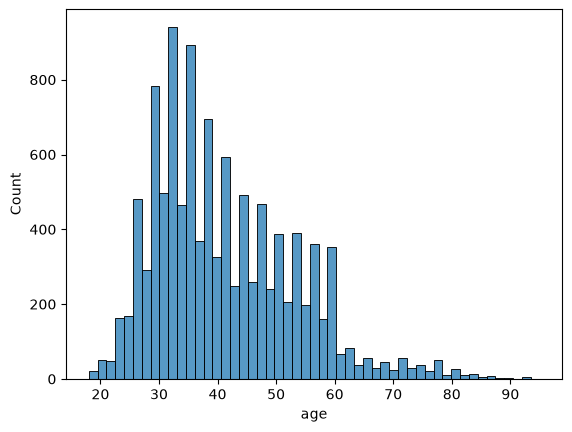

In [26]:
sns.histplot(data=df, x="age");

In [27]:
df["job"].value_counts()

job
management       2566
blue-collar      1944
technician       1823
admin.           1334
services          923
retired           778
self-employed     405
student           360
unemployed        357
entrepreneur      328
housemaid         274
unknown            70
Name: count, dtype: int64

> This is some bias here as there is a larger number of `management`, `blue-collar` and `technician` compared to the rest

In [28]:
print(df["loan"].value_counts())
print(df["housing"].value_counts())

loan
no     9702
yes    1460
Name: count, dtype: int64
housing
no     5881
yes    5281
Name: count, dtype: int64


> Not many people are taking loans in this bank

## **Age vs Balance**

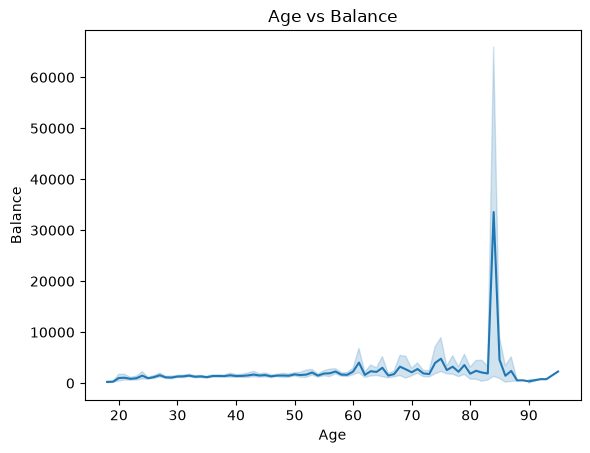

In [29]:
sns.lineplot(data=df, x="age", y="balance")
plt.xlabel("Age")
plt.ylabel("Balance")
plt.title("Age vs Balance");

> There seems to be an anomalous result in this dataset since there is a spike in the people aged between 80-90. We will investigate to find if this is only for 1 result only

In [30]:
for n in range (10, 60, 10):
    print(f"The average age of the top {n} people with the highest balance: {round(df.nlargest(n, "balance").age.mean(), 1)}")
    print(f"The average balance of the top {n} people: {round(df["balance"].nlargest(n).mean(), -3)}")
    print("="*50)

The average age of the top 10 people with the highest balance: 60.6
The average balance of the top 10 people: 56000.0
The average age of the top 20 people with the highest balance: 56.2
The average balance of the top 20 people: 44000.0
The average age of the top 30 people with the highest balance: 52.5
The average balance of the top 30 people: 38000.0
The average age of the top 40 people with the highest balance: 50.0
The average balance of the top 40 people: 35000.0
The average age of the top 50 people with the highest balance: 49.2
The average balance of the top 50 people: 32000.0


> This shows that only the older genration has more wealth in the bank which could be useful information for targeted ads and exclusive services. Also, this could help push ads to the younger genration with larger deals and offers

## **Age vs Balance by Deposit**

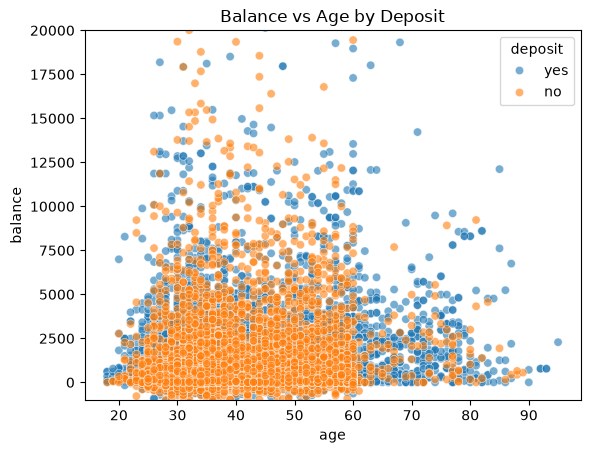

In [31]:
sns.scatterplot(data=df, x="age", y="balance", hue="deposit", alpha=0.6)
plt.ylim(-1000, 20000) # To ignore anomalous results
plt.title("Balance vs Age by Deposit");

> This unforunately doesn't show a clear correclation between the age and balance against making a deposit

## **Duration vs Deposit**

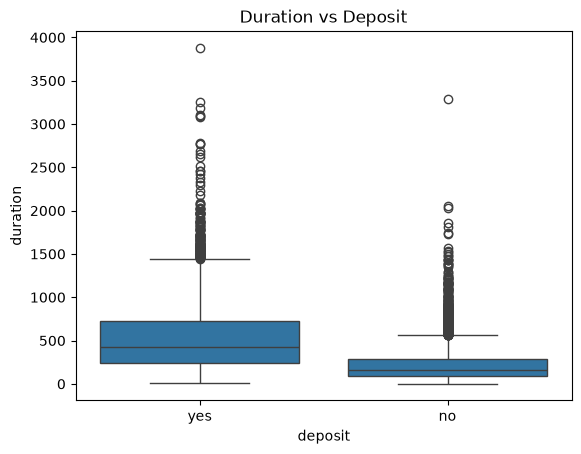

In [32]:
sns.boxplot(data=df, x="deposit", y="duration")
plt.title("Duration vs Deposit");

> This boxplot shows that as the call duration increases, the probability of creating a deposit increases where it can be evidient that the boxplot of the "no" is very thin. This could be explained by the fact that uninterseted people do not tend to stay on the call for long. Although this may seem common sense, it can be a good indcator that a person who spent more time on the call is more likely to create a deposit, so it would be fruitful to push more ads encouraging these group of people

## **Previous Outcome vs Deposit**

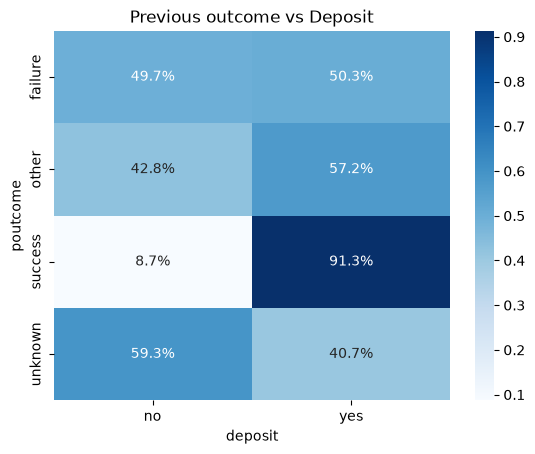

In [33]:
# We create a table where the index = previous outcome of campaign, columns = deposit,
# and values = sum of people in each category
tab = pd.crosstab(df["poutcome"], df["deposit"], normalize="index")
# We plot a heatmap as a percentage to 1 dp
sns.heatmap(data=tab, annot=True, cmap="Blues", fmt=".1%")
plt.title("Previous outcome vs Deposit");

> This heatmap shows that when the previous campaign was a success, there is an astonishing 91.3% of people creating deposits. While for the outcomes like `other`, `unknown` and `failure`, the percentage of people is split 50/50 suggesting that there is still a chance for them to make a deposit

## **Deposit vs Job Categories**

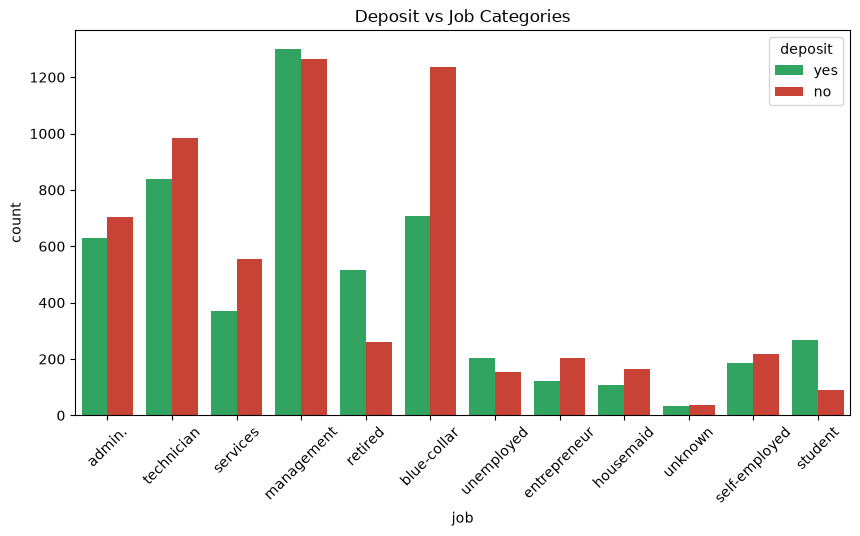

In [34]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="job", hue="deposit", palette={"no": "#E12F1C", "yes": "#1FB75F"})
plt.title("Deposit vs Job Categories")
plt.xticks(rotation=45);

> This graph shows that the bank attracts and has made campaigns deticated more to `blue-collar`, `management`, `technician` and `admin`. However, the least promising job is the `blue-collar` since the `yes` to `no` ratio here is shocking where the number of blue-collar workers who didn't deposit is about twice as much as the number who did. Oddly enough, the most promising ratio is the `retired`, suggesting that the bank gives more offers for these people. That can explain why the wealthiest people in the bank are also very old.

## **Deposit vs Month**

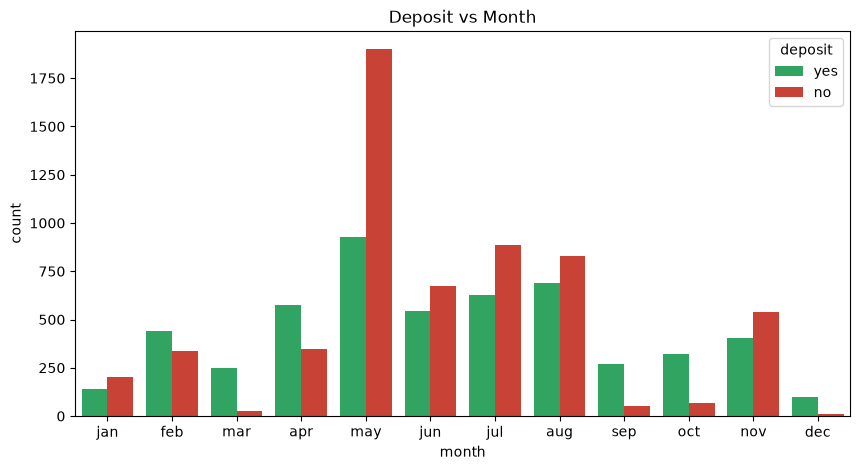

In [35]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df,
            x="month",
            hue="deposit",
            palette={"no": "#E12F1C", "yes": "#1FB75F"},
            order=["jan", "feb", "mar", "apr", "may", "jun",
                    "jul", "aug", "sep", "oct", "nov", "dec"]
                    )
plt.title("Deposit vs Month");

> This graph outlines the efficency of the campain because it shows that the campaign reached out to the most amount of people in may, yet with a low success rate. It is apparent that the month with the highest `yes` to `no` ratio is **march, september and october** where the proportion of `yes` outweigh the `no` by a significant amount

<a id='code'></a>
# **Encoding**

### <u> Part I: Encoding Boolean </u>

**Boolean Columns:** `housing`, `loan`, `deposit`

In [36]:
print("Deposit: ", df["deposit"].unique())
print("Housing: ", df["housing"].unique())
print("Loan: ", df["loan"].unique())

Deposit:  <StringArray>
['yes', 'no']
Length: 2, dtype: str
Housing:  <StringArray>
['yes', 'no']
Length: 2, dtype: str
Loan:  <StringArray>
['no', 'yes']
Length: 2, dtype: str


In [37]:
df["deposit"] = df["deposit"].map({"no": 0, "yes": 1})
df["housing"] = df["housing"].map({"no": 0, "yes": 1})
df["loan"] = df["loan"].map({"no": 0, "yes": 1})

### <u> Part II: Encoding Ordinal Feautres </u>

**Ordinal Columns:** `education`, `month`

In [38]:
df["education"].unique()

<StringArray>
['secondary', 'tertiary', 'primary', 'unknown']
Length: 4, dtype: str

In [39]:
df["education"] = df["education"].map({"unknown": 0, "primary": 1, "secondary": 2, "tertiary": 3})

In [40]:
df["month"] = df["month"].map({"jan": 1,"feb": 2,"mar": 3,"apr": 4,"may": 5,"jun": 6,
                               "jul": 7,"aug": 8,"sep": 9,"oct": 10,"nov": 11,"dec": 12})

### <u> Part III: Encoding Nominal Features </u>

**Nominal Columns:** `job`, `martial`, `poutcome`

>**NOTE:** I will encode them using One-Hot Encoding becuase using `LabelEncoder()` will create random labels for the values which can create issues when building the neural netwrok since this assumes that one job is "better" than the other. If `admin= 1` and `blue-collar= 2`, the network will assume that that `blue-collar` is 2 times greater than `admin`

In [41]:
# We used drop_first because if all values are 0, then it must be the dropped value, reducing the dataset size
df = pd.get_dummies(df, columns=["job", "marital", "poutcome"], drop_first=True, dtype=int)

In [42]:
# Checking to see the columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 27 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   age                11162 non-null  int64
 1   education          11162 non-null  int64
 2   balance            11162 non-null  int64
 3   housing            11162 non-null  int64
 4   loan               11162 non-null  int64
 5   month              11162 non-null  int64
 6   duration           11162 non-null  int64
 7   campaign           11162 non-null  int64
 8   pdays              11162 non-null  int64
 9   previous           11162 non-null  int64
 10  deposit            11162 non-null  int64
 11  job_blue-collar    11162 non-null  int64
 12  job_entrepreneur   11162 non-null  int64
 13  job_housemaid      11162 non-null  int64
 14  job_management     11162 non-null  int64
 15  job_retired        11162 non-null  int64
 16  job_self-employed  11162 non-null  int64
 17  job_services       1116

<a id='prepro'></a>
# **Preprosessing**

In [43]:
x = df.drop(columns="deposit")
y = df["deposit"]

xtrain, xtest, ytrain, ytest = train_test_split(x, y, test_size=0.2, random_state=42)

In [44]:
scaler = StandardScaler()

# Fitting and transforming training data
xtrain_scaled = scaler.fit_transform(xtrain)
# Transforming only the testing data
xtest_scaled = scaler.transform(xtest)

In [45]:
pca = PCA(n_components=3)

xtrain = pca.fit_transform(xtrain_scaled)
xtest = pca.transform(xtest_scaled)

<a id='cluster'></a>
# **Data Clustering**

### <u> Part I: K-means Clustering </u>

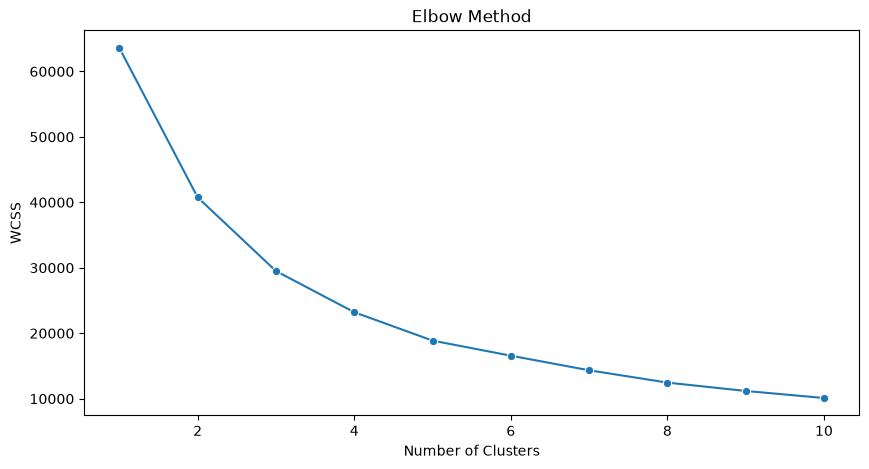

In [46]:
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, n_init=10, random_state=42)
    kmeans.fit(xtrain)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(10,5))
sns.lineplot(x=range(1,11), y=wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS");

> It can be evident that **3 clusters** is the most suitable configuration of clusters

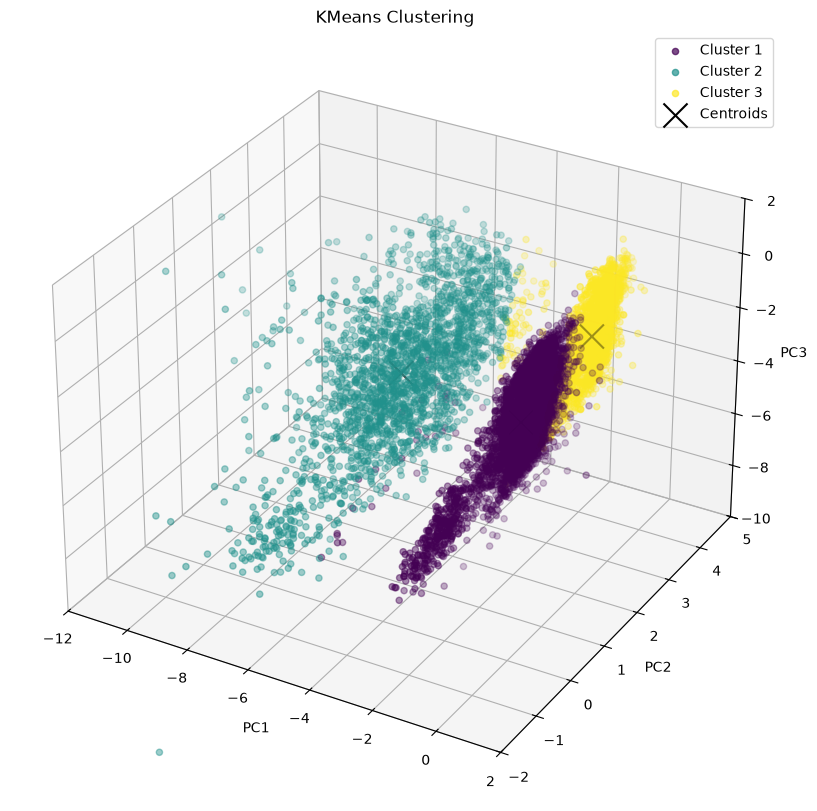

In [47]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(xtrain)

fig = plt.figure(figsize=(10,10))
ax = fig.add_subplot(projection='3d')

colours = ['#440154', '#21918c', '#fde725']
for cluster_id in range(3):
    mask = (kmeans_labels == cluster_id)
    ax.scatter(
        xtrain[mask, 0], xtrain[mask, 1], xtrain[mask, 2],
        alpha=0.7,
        c=colours[cluster_id],
        label=f'Cluster {cluster_id+1}',
    )

centroids = kmeans.cluster_centers_
ax.scatter(centroids[:, 0], centroids[:, 1], centroids[:, 2], marker="x", s=300, c="black", label="Centroids")

# This was done to eliminate noisy points and focus on the cluster structure itself
ax.set_xlim(-12, 2)
ax.set_ylim(-2, 5)
ax.set_zlim(-10, 2)

plt.xlabel("PC1")
plt.ylabel("PC2")
ax.set_zlabel("PC3")
plt.title("KMeans Clustering")
plt.legend(loc="upper right");

##### **NOTE:** Although 3D plots look attractive, they fail to represent data properly so we will use pairwair projections for a more accurate reading

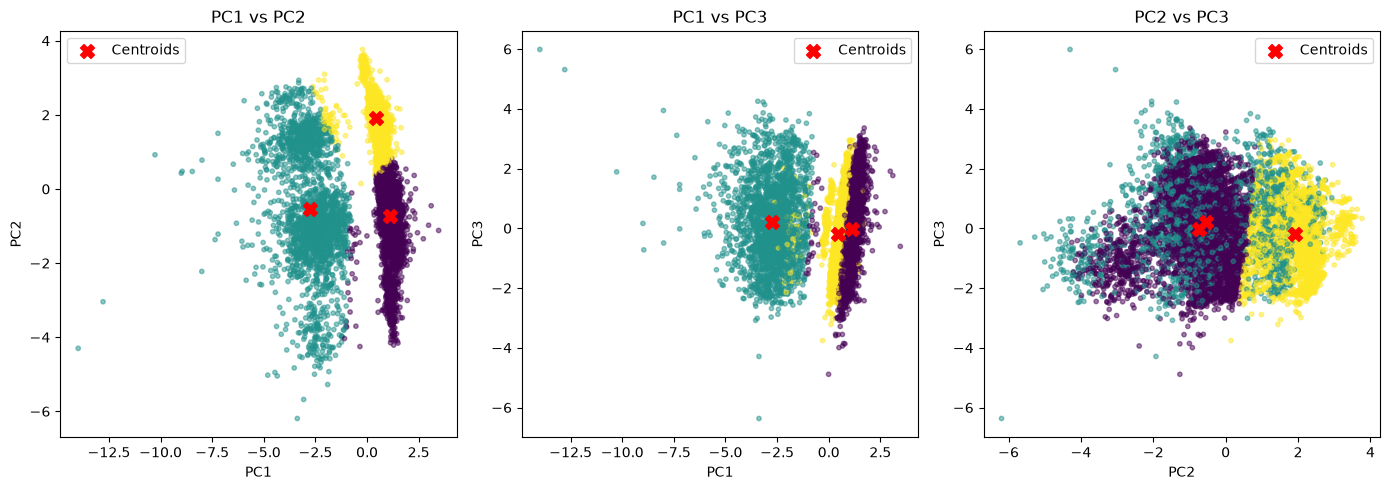

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

# PC1 vs PC2
axes[0].scatter(xtrain[:, 0], xtrain[:, 1], c=kmeans_labels, cmap="viridis", alpha=0.5, s=10)
axes[0].scatter(centroids[:, 0], centroids[:, 1], c="red", marker="X", s=100, label="Centroids")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].set_title("PC1 vs PC2")
axes[0].legend()

# PC1 vs PC3
axes[1].scatter(xtrain[:, 0], xtrain[:, 2], c=kmeans_labels, cmap="viridis", alpha=0.5, s=10)
axes[1].scatter(centroids[:, 0], centroids[:, 2], c="red", marker="X", s=100, label="Centroids")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC3")
axes[1].set_title("PC1 vs PC3")
axes[1].legend()

# PC2 vs PC3
axes[2].scatter(xtrain[:, 1], xtrain[:, 2], c=kmeans_labels, cmap="viridis", alpha=0.5, s=10)
axes[2].scatter(centroids[:, 1], centroids[:, 2], c="red", marker="X", s=100, label="Centroids")
axes[2].set_xlabel("PC2")
axes[2].set_ylabel("PC3")
axes[2].set_title("PC2 vs PC3")
axes[2].legend()

plt.tight_layout()
plt.show()

In [49]:
centroids = kmeans.cluster_centers_
clusters = pd.DataFrame(centroids, columns=['PC1', 'PC2', 'PC3'], index=['Cluster 1', 'Cluster 2', 'Cluster 3'])
print(clusters)

                PC1       PC2       PC3
Cluster 1  1.107239 -0.738248 -0.012637
Cluster 2 -2.762438 -0.548316  0.225421
Cluster 3  0.428180  1.915924 -0.183468


### <u> Part II: Hierarchial Clustering </u>

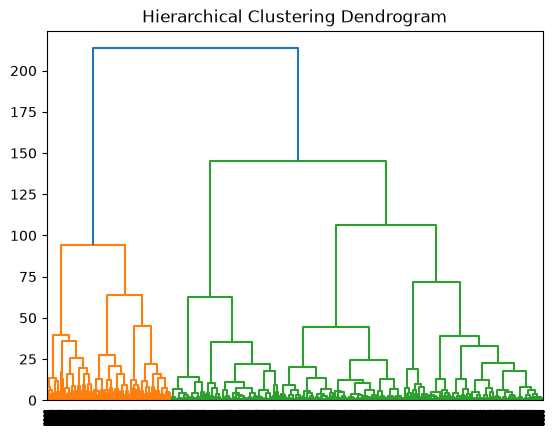

In [50]:
scipy.cluster.hierarchy.dendrogram(scipy.cluster.hierarchy.linkage(xtrain, method="ward"))
plt.xlabel("")
plt.title("Hierarchical Clustering Dendrogram");

##### From this graph, we can see that the optimal number of clusters is still **3**

In [51]:
hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage="ward")
xtrain_df = pd.DataFrame(xtrain, columns= ["PC1", "PC2", "PC3"])
xtrain_df["Hierarchical_Cluster"] = hc.fit_predict(xtrain)

### <u> Part III: Comparison </u>

In [52]:
print("Kmeans Centriods")
centroids = kmeans.cluster_centers_
clusters = pd.DataFrame(centroids, columns=['PC1', 'PC2', 'PC3'], index=['Cluster 1', 'Cluster 2', 'Cluster 3'])
print(clusters)
print("="*50)
print("Hierarchial Centriods")
print(xtrain_df.groupby("Hierarchical_Cluster").mean())

Kmeans Centriods
                PC1       PC2       PC3
Cluster 1  1.107239 -0.738248 -0.012637
Cluster 2 -2.762438 -0.548316  0.225421
Cluster 3  0.428180  1.915924 -0.183468
Hierarchial Centriods
                           PC1       PC2       PC3
Hierarchical_Cluster                              
0                     1.088516 -0.624093 -0.066282
1                    -2.708016 -0.496267  0.207689
2                     0.473313  2.060552 -0.077526


> From the centriods here, we can see that hierarchial clustering and K-means preformed similarly as the centriods have similar values.

<a id='cnn'></a>
# **CNN and Model Evaluation**

### <u> Part I: Reshaping </u>

In [53]:
xtrain_cnn = np.expand_dims(xtrain, axis=2)
xtest_cnn  = np.expand_dims(xtest, axis=2)

### <u> Part II: Creating CNN Architecture </u>

In [54]:
model = Sequential()

model.add(Conv1D(filters=16, kernel_size=2, activation='relu', input_shape=(3, 1)))
model.add(BatchNormalization())
model.add(Dropout(0.25))


model.add(Conv1D(filters=32, kernel_size=2, activation='relu'))
model.add(BatchNormalization())
model.add(Dropout(0.25))

model.add(Flatten())
model.add(Dense(32, activation='relu'))
model.add(Dropout(0.25))

model.add(Dense(1, activation='sigmoid'))

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

c:\Users\PC\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### <u> Part III: Training </u>

In [55]:
history = model.fit(xtrain_cnn, ytrain, epochs=50, batch_size=32, validation_split=0.2)

Epoch 1/50
224/224 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.5741 - loss: 0.7214 - val_accuracy: 0.6433 - val_loss: 0.6460
Epoch 2/50
224/224 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6027 - loss: 0.6766 - val_accuracy: 0.6512 - val_loss: 0.6298
Epoch 3/50
224/224 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6062 - loss: 0.6693 - val_accuracy: 0.6568 - val_loss: 0.6263
Epoch 4/50
224/224 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6151 - loss: 0.6605 - val_accuracy: 0.6512 - val_loss: 0.6288
Epoch 5/50
224/224 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6179 - loss: 0.6577 - val_accuracy: 0.6517 - val_loss: 0.6281
Epoch 6/50
224/224 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.6175 - loss: 0.6529 - val_accuracy: 0.6495 - val_loss: 0.6271
Epoch 7/50
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6174 - loss: 0.6547 - val_accuracy: 0.6439 - val_loss: 0.6273
Epoch 8/50
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6268 - loss: 0.6496 - val_accuracy: 0.

In [56]:
loss, accuracy = model.evaluate(xtest_cnn, ytest)
print(f"Test Accuracy:{accuracy}")
print(f"Test Loss:{loss}")

70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6637 - loss: 0.6167
Test Accuracy:0.663681149482727
Test Loss:0.6167415380477905


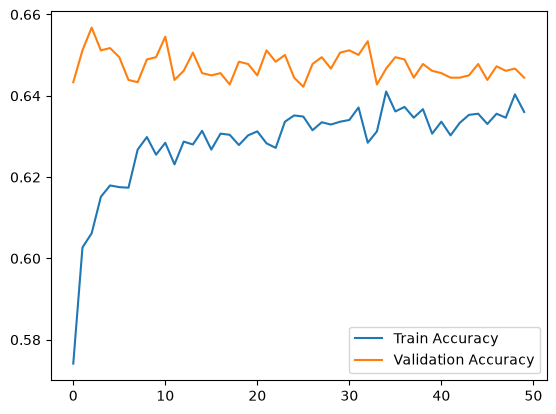

In [57]:
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.legend()
plt.show()

### <u> Part IV: Hyperparameter Tuning </u>

In [58]:
history = model.fit(xtrain_cnn, ytrain, epochs=20, batch_size=4, validation_split=0.2)

Epoch 1/20
1786/1786 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.6105 - loss: 0.6585 - val_accuracy: 0.6411 - val_loss: 0.6238
Epoch 2/20
1786/1786 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.6241 - loss: 0.6481 - val_accuracy: 0.6417 - val_loss: 0.6230
Epoch 3/20
1786/1786 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.6168 - loss: 0.6569 - val_accuracy: 0.6439 - val_loss: 0.6233
Epoch 4/20
1786/1786 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.6147 - loss: 0.6531 - val_accuracy: 0.6400 - val_loss: 0.6248
Epoch 5/20
1786/1786 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.6165 - loss: 0.6557 - val_accuracy: 0.6411 - val_loss: 0.6218
Epoch 6/20
1786/1786 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.6185 - loss: 0.6496 - val_accuracy: 0.6389 - val_loss: 0.6231
Epoch 7/20
1786/1786 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.6140 - loss: 0.6530 - val_accuracy: 0.6439 - val_loss: 0.6215
Epoch 8/20
1786/1786 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.6137 - loss: 0

loss, accuracy = model.evaluate(xtest_cnn, ytest)
print(f"Test Accuracy:{accuracy}")
print(f"Test Loss:{loss}")

##### It appears that after tuning, the accuracy is still at 0.64-0.66 This could be caused by numerous factors regarding the data. Such as: loss of information due to PCA, y imbalance, biased training data

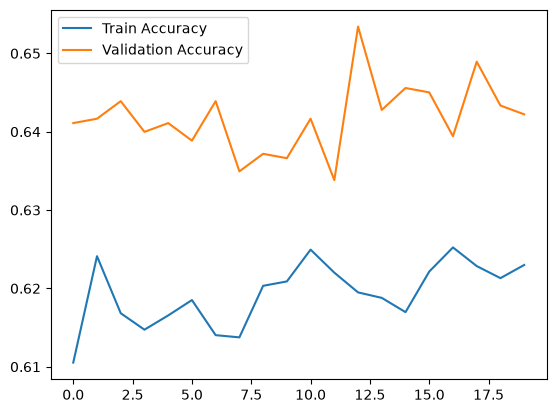

In [60]:
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.legend()
plt.show()

### <u> Part V: Model Evaluation </u>

In [61]:
y_pred_prob = model.predict(xtest_cnn)
ypred = (y_pred_prob >= 0.5).astype(int)

print("Accuracy:", round(accuracy_score(ytest, ypred), 2))
print("Precision:", round(precision_score(ytest, ypred), 2))
print("Recall:", round(recall_score(ytest, ypred), 2))
print("F1 Score:", round(f1_score(ytest, ypred), 2))

70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
Accuracy: 0.66
Precision: 0.78
Recall: 0.4
F1 Score: 0.53


### <u> Part VI: Confusion Matrix </u>

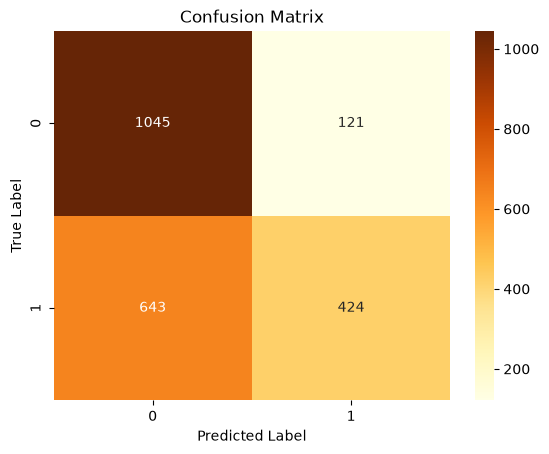

In [62]:
cm = confusion_matrix(ytest, ypred)

sns.heatmap(cm, annot=True, fmt="d", cmap="YlOrBr")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix");

<a id='conc'></a>
# **Conclusion:**
<ul>
  <li><p style="font-size: 24px;">The model detected a surprisingly high number of true negatives, suggesting a that the training dataset contained more deposit = 0. <p></li>
  <li><p style="font-size: 24px;">Unfortuantely, the model is worse than being random at detecting positives in general where it has a high accuracy but a very low recall</p></li>
  <li><p style="font-size: 24px;">It is apparent that the model doesn't have a balance between its precision and recall (due to the low f1-score)</p></li>
</ul>